# 06 · Analyses

1. **Position bias.** Listwise Llama on the same test queries, with candidates in v1's positives-first order, shuffled, and reversed.
2. **Stage-1 diagnostic.** Recall of the true references in Qwen3's top k, for k = 5, 10, 20, 50. This tests v1's "stage-1 recall loss" explanation.
3. **Contamination check.** The LLM's gain over Qwen3 for queries published before vs after Llama 3.2's knowledge cutoff. Meta's model card says: "The pretraining data has a cutoff of December 2023."
4. **LLM reliability.** Listwise outputs that were partial or unparseable.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

RESEARCH = Path.cwd().parent if Path.cwd().name == "v2" else Path.cwd()
sys.path.insert(0, str(RESEARCH))

import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

from src.figures import save, setup_style
setup_style()

In [2]:
BENCHES = ["concept", "random"]
SPLIT = "test"
CUTOFF = "2023-12-31"
BASELINE = "qwen"

In [3]:
import json
from src.pipeline_v2 import load_eval_sets, load_runs
from src.stats_v2 import contamination_split, per_query, position_bias, stage1_recall

C = json.loads((RESEARCH / "v2" / "config.json").read_text())
TAG = f"{C['fields']}_{C['max_chars']}_{C['query_max_chars']}"
runs = {b: load_runs(b, TAG, split=SPLIT) for b in BENCHES}

### 1 · Position bias

If the LLM uses content rather than position, MRR and R-precision should not depend on the input order.

In [4]:
pb = {}
for bench, df in runs.items():
    pb[bench] = position_bias(df[df["seed"].isin(df[df["order"] != "shuffled"]["seed"].unique())], "llama")
    print(bench); display(pb[bench])

concept


,order,mrr,rprec,top1,queries
0,original,0.9786,74.0661,0.9746,118
1,reversed,0.2745,19.8994,0.1695,118
2,shuffled,0.6085,43.1042,0.3559,118


random


,order,mrr,rprec,top1,queries
0,original,0.9466,72.2950,0.9407,118
1,reversed,0.3340,29.9876,0.2288,118
2,shuffled,0.6627,46.3262,0.4407,118


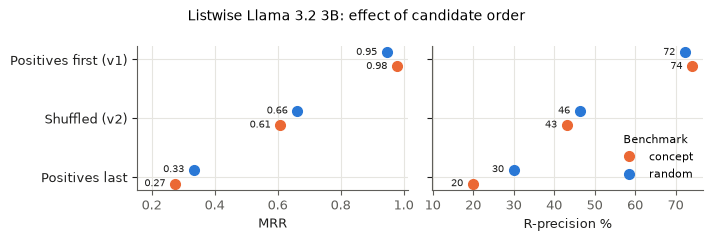

In [5]:
from src.figures import fig_position_bias
save(fig_position_bias(pb), "06_position_bias")

**Figure (06_position_bias).** Listwise Llama 3.2 3B on the same test queries and seed, with candidates in three input orders. "Positives first" reproduces v1's order. Differences between rows measure position bias.

### 2 · Stage-1 recall (Qwen3)

`queries_full_recall` is the number of queries whose references all survive the cut. Compare it with the two-stage result in `05_stats`.

In [6]:
recalls = {}
for bench, df in runs.items():
    recalls[bench] = stage1_recall(df, "qwen")
    print(bench); display(recalls[bench])

concept


,mean,min,queries_full_recall,queries
recall@5,0.6379,0.1667,20,118
recall@10,0.8898,0.3636,65,118
recall@20,0.9788,0.4545,105,118
recall@50,1.0000,1.0000,118,118


random


,mean,min,queries_full_recall,queries
recall@5,0.6759,0.2000,24,118
recall@10,0.9251,0.5000,77,118
recall@20,0.9901,0.7273,109,118
recall@50,1.0000,1.0000,118,118


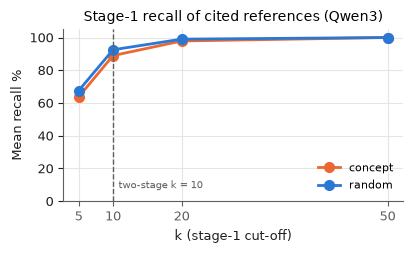

In [7]:
from src.figures import fig_stage1_recall
save(fig_stage1_recall(recalls, k_used=C["stage1_k"]), "06_stage1_recall")

**Figure (06_stage1_recall).** Mean share of each query's cited references that Qwen3 ranks in its top k. Where the curve is close to 100% at the two-stage cut-off, stage 1 loses almost nothing, so a two-stage drop cannot be blamed on stage-1 recall.

### 3 · Contamination check

**Caveat:** almost all queries were published before the cutoff, so the "after" group is tiny. Read this as a limitation, not as evidence either way.

In [8]:
for bench, df in runs.items():
    ds = load_eval_sets(bench)
    dates = {s["pi_id"]: s["pi_date"] for s in ds["sets"]}
    print(bench); display(contamination_split(per_query(df), dates, CUTOFF, "llama", BASELINE))

concept

,period,queries,llm,baseline,gain
0,after cutoff,1,50.9091,100.0000,-49.0909
1,before cutoff,117,41.9536,79.9046,-37.9511


random


,period,queries,llm,baseline,gain
0,after cutoff,1,38.1818,100.0000,-61.8182
1,before cutoff,117,43.9737,86.8651,-42.8914


### 4 · LLM output reliability

In [9]:
for bench, df in runs.items():
    llm = df[df["method"].str.startswith(("llama", "qwen→llama")) & (df["method"] != "llama+minilm")]
    print(bench); display(llm.groupby(["method", "order"])["status"].value_counts().unstack(fill_value=0))

concept


status                             ok  parse_fail  partial
method                  order                             
llama                   original   61           1       56
                        reversed   77           1       40
                        shuffled  360           0      230
llama-pointwise         shuffled  118           0        0
llama-window            shuffled  581           0        9
qwen→llama_k10_shuffled shuffled  587           0        3

random


status                             ok  parse_fail  partial
method                  order                             
llama                   original   66           0       52
                        reversed   78           1       39
                        shuffled  365           3      222
llama-pointwise         shuffled  118           0        0
llama-window            shuffled  576           0       14
qwen→llama_k10_shuffled shuffled  586           0        4

### Findings

- **Position bias explains v1.** The test queries were run with listwise Llama on the same candidates in three orders.
  - With v1's positives-first order, it scores MRR 0.95 / 0.98 and R-precision 72 / 74 (`random` / `concept`), reproducing and exceeding v1's headline MRR 0.84.
  - Shuffled, it scores 0.66 / 0.61.
  - With positives last, it drops to MRR 0.33 / 0.27 and R-precision 30 / 20, **below chance** (about 0.56 MRR and 33% R-precision).
  - Top-1 accuracy goes from 94–97% to 17–23%. The model ranks largely by input position, not content.
- **Stage-1 recall is not the bottleneck.**
  - Qwen3's top 10 holds 93% (`random`) and 89% (`concept`) of the cited references on average. Its top 20 holds 99% and 98%.
  - The two-stage drop seen in `05_stats` (13.0 and 10.4 points below Qwen3 alone) therefore comes from the Llama reranking step, not from references lost at stage 1. This contradicts v1's explanation (audit F5).
- **Contamination cannot be tested with these queries.** Llama 3.2's pretraining data has a cutoff of December 2023 (Meta model card). Only two of the 168 queries are later, and only one is in the test split. The before/after comparison is therefore not interpretable. Testing contamination would need queries published after the cutoff, which is a candidate for the full-corpus experiment.
- **Listwise output is unreliable at full length.**
  - Full-list Llama returns a partial ranking in 38% of calls (452 of 1,180 across both benchmarks) and an unparseable one in 3.
  - With the sliding window (at most 10 candidates per call), 23 of 1,180 queries had any partial window.
  - Pointwise calls never failed.